# Task-6 Week-3.

**Dataset :-** 'Admission_Prediction.csv'

**Objective :-Perform complex Bayesian statistical analysis to incorporate prior knowledge and uncertainty into predictive modeling of applicant acceptance probabilities, enhancing probabilistic decision-making.

In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    classification_report
)

np.random.seed(42)

In [2]:
# Load the dataset

df = pd.read_csv(
    "Admission_Prediction.csv"
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully.
Dataset shape: (1000, 14)

First five records:


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Year,Application_Date,University_Name,region,Admission Status
0,104,317,104,2,4.5,4.0,8.47,0,0.57,2022,2022-01-03,Indian Institute of Technology Bombay,West,Rejected
1,170,311,99,2,2.5,3.0,7.98,0,0.65,2022,2022-01-09,Indian Institute of Technology Delhi,North,Rejected
2,138,316,100,2,1.5,3.0,8.16,1,0.71,2022,2022-01-12,Indian Institute of Technology Delhi,North,Rejected
3,147,315,105,3,2.0,2.5,8.48,0,0.75,2022,2022-01-13,Indian Institute of Technology Delhi,North,Accepted
4,117,299,102,3,4.0,3.5,8.62,0,0.56,2022,2022-01-14,Indian Institute of Technology Delhi,North,Rejected



Column names:
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Year', 'Application_Date', 'University_Name', 'region', 'Admission Status']


In [3]:
# clean the data

# Select academic and application predictors
features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research"
]

target = "Admission Status"

# Verify required columns
required_columns = features + [target]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Keep only columns required for this analysis
data = df[required_columns].copy()

# Convert predictors to numeric
for col in features:
    data[col] = pd.to_numeric(
        data[col], errors="coerce"
    )

# Standardize the text format of the target labels
data[target] = (
    data[target]
    .astype("string")
    .str.strip()
    .str.title()
)

# Keep only valid outcomes
data = data[
    data[target].isin(["Accepted", "Rejected"])
].copy()

# Remove missing and infinite predictor values
data[features] = data[features].replace(
    [np.inf, -np.inf], np.nan
)

data = data.dropna(
    subset=features + [target]
).reset_index(drop=True)

# Encode the target:
# Accepted = 1, Rejected = 0
data["Accepted_Binary"] = (
    data[target] == "Accepted"
).astype(int)

print("Cleaned dataset shape:", data.shape)

print("\nAdmission outcome counts:")
print(data[target].value_counts())

print("\nMissing values:")
print(data[features + [target]].isnull().sum())

Cleaned dataset shape: (1000, 9)

Admission outcome counts:
Admission Status
Rejected    565
Accepted    435
Name: count, dtype: Int64

Missing values:
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Admission Status     0
dtype: int64


In [4]:
# target and predict

X = data[features].copy()

y = data["Accepted_Binary"].copy()

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Predictor shape: (1000, 7)
Target shape: (1000,)

Target distribution:
Accepted_Binary
0    565
1    435
Name: count, dtype: int64


In [5]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print(
    "Training acceptance rate:",
    round(y_train.mean(), 3)
)

print(
    "Testing acceptance rate:",
    round(y_test.mean(), 3)
)

Training records: 800
Testing records: 200
Training acceptance rate: 0.435
Testing acceptance rate: 0.435


In [6]:
# Scale the predictor variables

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled training data:")
print(pd.DataFrame(
    X_train_scaled,
    columns=features
).head())

Scaled training data:
   GRE Score  TOEFL Score  University Rating       SOP       LOR      CGPA  \
0  -1.258919    -0.473424          -0.766492  0.579580 -0.458988 -1.499876   
1  -0.220100    -0.604024          -0.013183 -1.363690 -0.458988 -0.548719   
2  -0.220100     0.310174           1.493435 -1.946671  1.249405 -0.007544   
3  -1.481524     0.310174          -0.766492 -0.392055 -0.572881 -0.958701   
4  -0.294301     1.093773          -0.013183 -0.975036  0.679940  1.042009   

   Research  
0  1.007528  
1 -0.992528  
2  1.007528  
3  1.007528  
4  1.007528  


In [7]:
# Fit Bayesian logistic regression with a Laplace approximation

# The priors match the original model: alpha ~ Normal(0, 1.5)
# and each coefficient ~ Normal(0, 1).
X_design = np.column_stack([
    np.ones(len(X_train_scaled)),
    X_train_scaled
])
y_train_array = y_train.to_numpy(dtype=float)
prior_sd = np.concatenate([[1.5], np.ones(len(features))])
prior_precision = 1 / prior_sd**2

def negative_log_posterior(parameters):
    log_odds = X_design @ parameters
    negative_log_likelihood = np.sum(
        np.logaddexp(0, log_odds) - y_train_array * log_odds
    )
    negative_log_prior = 0.5 * np.sum(
        parameters**2 * prior_precision
    )
    return negative_log_likelihood + negative_log_prior

def negative_log_posterior_gradient(parameters):
    probabilities = expit(X_design @ parameters)
    return (
        X_design.T @ (probabilities - y_train_array)
        + parameters * prior_precision
    )

fit = minimize(
    negative_log_posterior,
    x0=np.zeros(X_design.shape[1]),
    jac=negative_log_posterior_gradient,
    method="L-BFGS-B",
    options={"maxiter": 2000, "ftol": 1e-12, "gtol": 1e-8, "maxls": 50}
)

if not fit.success:
    raise RuntimeError(
        f"Bayesian logistic regression did not converge: {fit.message}"
    )

# Approximate posterior covariance using the inverse Hessian at the MAP.
map_probabilities = expit(X_design @ fit.x)
hessian_weights = map_probabilities * (1 - map_probabilities)
weighted_design = X_design * hessian_weights[:, None]
posterior_hessian = (
    X_design.T @ weighted_design
    + np.diag(prior_precision)
)
hessian_eigenvalues = np.linalg.eigvalsh(posterior_hessian)
if hessian_eigenvalues.min() <= 0:
    raise FloatingPointError(
        "The posterior Hessian is not positive definite."
    )
posterior_covariance = np.linalg.inv(posterior_hessian)

# Draw from the Gaussian Laplace approximation to the posterior.
rng = np.random.default_rng(42)
posterior_draws = rng.multivariate_normal(
    mean=fit.x,
    cov=posterior_covariance,
    size=4000,
    check_valid="raise"
)
alpha_samples = posterior_draws[:, 0]
beta_samples = posterior_draws[:, 1:]

Posterior summary (95% central credible intervals):


,Parameter,Posterior_Mean,Posterior_SD,Lower_95_CrI,Upper_95_CrI
0,alpha,-0.3035,0.0785,-0.4610,-0.1513
1,GRE Score,0.3119,0.0840,0.1494,0.4784
2,TOEFL Score,0.2849,0.0795,0.1295,0.4415
3,University Rating,0.1623,0.0837,-0.0012,0.3243
4,SOP,0.2731,0.0846,0.1081,0.4375
5,LOR,0.0905,0.0856,-0.0775,0.2544
6,CGPA,0.3332,0.0874,0.1639,0.5011
7,Research,0.2695,0.0808,0.1137,0.4258


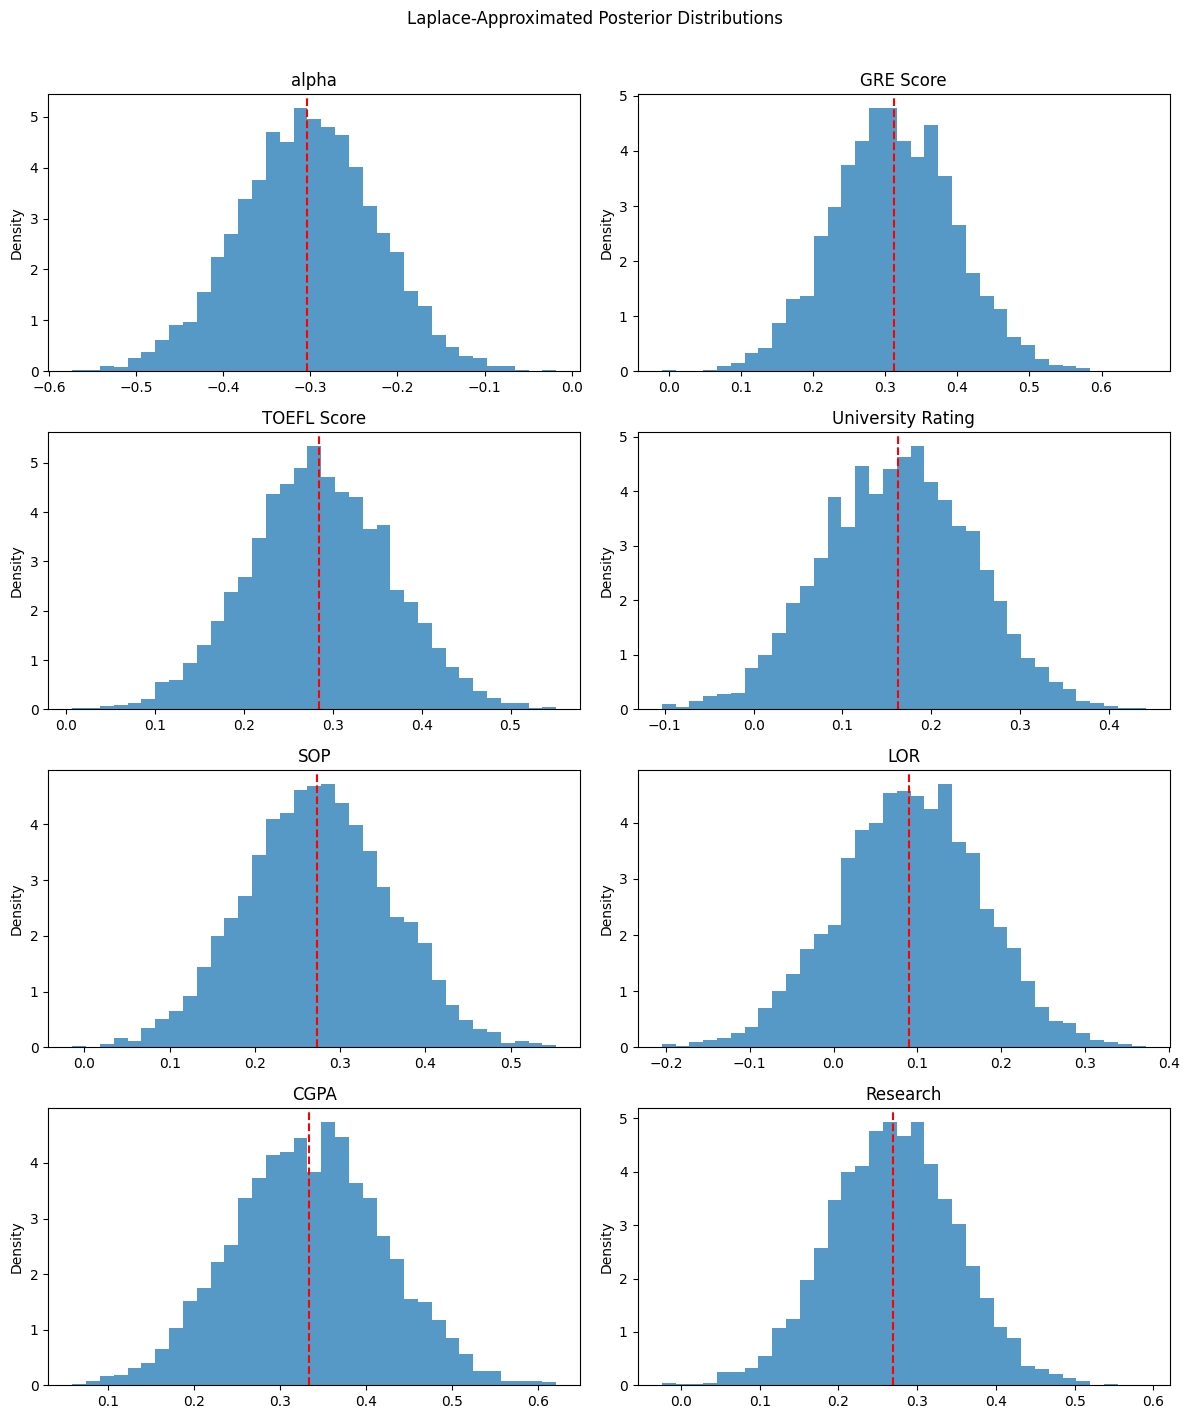

In [8]:
# Summarize and plot the approximate posterior distributions

parameter_names = ["alpha"] + features
parameter_draws = np.column_stack([alpha_samples, beta_samples])
posterior_summary = pd.DataFrame({
    "Parameter": parameter_names,
    "Posterior_Mean": parameter_draws.mean(axis=0),
    "Posterior_SD": parameter_draws.std(axis=0, ddof=1),
    "Lower_95_CrI": np.quantile(parameter_draws, 0.025, axis=0),
    "Upper_95_CrI": np.quantile(parameter_draws, 0.975, axis=0)
})

print("Posterior summary (95% central credible intervals):")
display(posterior_summary.round(4))

fig, axes = plt.subplots(4, 2, figsize=(12, 14))
for index, (name, samples) in enumerate(
    zip(parameter_names, parameter_draws.T)
):
    axes.flat[index].hist(samples, bins=35, density=True, alpha=0.75)
    axes.flat[index].axvline(samples.mean(), color="red", linestyle="--")
    axes.flat[index].set_title(name)
    axes.flat[index].set_ylabel("Density")

fig.suptitle("Laplace-Approximated Posterior Distributions", y=1.01)
fig.tight_layout()
plt.show()

In [9]:
# Check the optimizer and Laplace approximation

print("Optimizer converged:", fit.success)
print("Optimizer message:", fit.message)
print(
    "Gradient norm at the posterior mode:",
    f"{np.linalg.norm(negative_log_posterior_gradient(fit.x)):.3e}"
)
print(
    "Smallest posterior Hessian eigenvalue:",
    f"{hessian_eigenvalues.min():.4f}"
)
print("Gaussian posterior draws:", len(posterior_draws))

print("\nPosterior means and 95% credible intervals:")
display(posterior_summary.round(4))

Optimizer converged: True
Optimizer message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
Gradient norm at the posterior mode: 4.751e-05
Smallest posterior Hessian eigenvalue: 108.7481
Gaussian posterior draws: 4000

Posterior means and 95% credible intervals:


,Parameter,Posterior_Mean,Posterior_SD,Lower_95_CrI,Upper_95_CrI
0,alpha,-0.3035,0.0785,-0.4610,-0.1513
1,GRE Score,0.3119,0.0840,0.1494,0.4784
2,TOEFL Score,0.2849,0.0795,0.1295,0.4415
3,University Rating,0.1623,0.0837,-0.0012,0.3243
4,SOP,0.2731,0.0846,0.1081,0.4375
5,LOR,0.0905,0.0856,-0.0775,0.2544
6,CGPA,0.3332,0.0874,0.1639,0.5011
7,Research,0.2695,0.0808,0.1137,0.4258


In [10]:
# Generate posterior acceptance probabilities from the approximate draws


# Calculate log-odds for every posterior draw
test_log_odds = (
    alpha_samples[:, None]
    + beta_samples @ X_test_scaled.T
)

# Convert log-odds into acceptance probabilities
test_probability_draws = expit(test_log_odds)

# Summarize the posterior predictive probabilities
probability_mean = test_probability_draws.mean(axis=0)

probability_lower = np.quantile(
    test_probability_draws, 0.025, axis=0
)

probability_upper = np.quantile(
    test_probability_draws, 0.975, axis=0
)

# Create results table
results = X_test.reset_index(drop=True).copy()

results["Actual_Status"] = (
    y_test.reset_index(drop=True)
    .map({1: "Accepted", 0: "Rejected"})
)

results["Predicted_Acceptance_Probability"] = (
    probability_mean
)

results["Lower_95_CrI"] = probability_lower
results["Upper_95_CrI"] = probability_upper

# Use 0.50 only as an illustrative classification threshold
results["Predicted_Status"] = np.where(
    results["Predicted_Acceptance_Probability"] >= 0.50,
    "Accepted",
    "Rejected"
)

print("Posterior prediction results:")
display(results.head(10).round(4))

Posterior prediction results:


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Actual_Status,Predicted_Acceptance_Probability,Lower_95_CrI,Upper_95_CrI,Predicted_Status
0,333,119,5,5.0,4.5,9.78,1,Accepted,0.9018,0.8504,0.9398,Accepted
1,312,120,3,3.0,4.0,7.71,0,Rejected,0.3336,0.2344,0.4457,Rejected
2,324,100,3,4.0,5.0,8.64,1,Accepted,0.5609,0.4597,0.6587,Accepted
3,312,116,4,3.5,1.5,8.45,1,Accepted,0.5222,0.3967,0.6452,Accepted
4,300,94,3,3.0,3.0,8.54,0,Accepted,0.1703,0.1204,0.2299,Rejected
5,334,117,5,4.0,4.5,9.07,1,Accepted,0.8212,0.7535,0.8775,Accepted
6,311,104,3,4.5,4.5,8.43,0,Rejected,0.3838,0.3020,0.4712,Rejected
7,318,103,2,2.9,3.5,9.16,0,Accepted,0.3545,0.2845,0.4310,Rejected
8,302,97,1,1.4,5.0,9.48,1,Accepted,0.3045,0.1781,0.4561,Rejected
9,300,115,2,5.0,3.4,8.75,1,Accepted,0.5707,0.4591,0.6782,Accepted


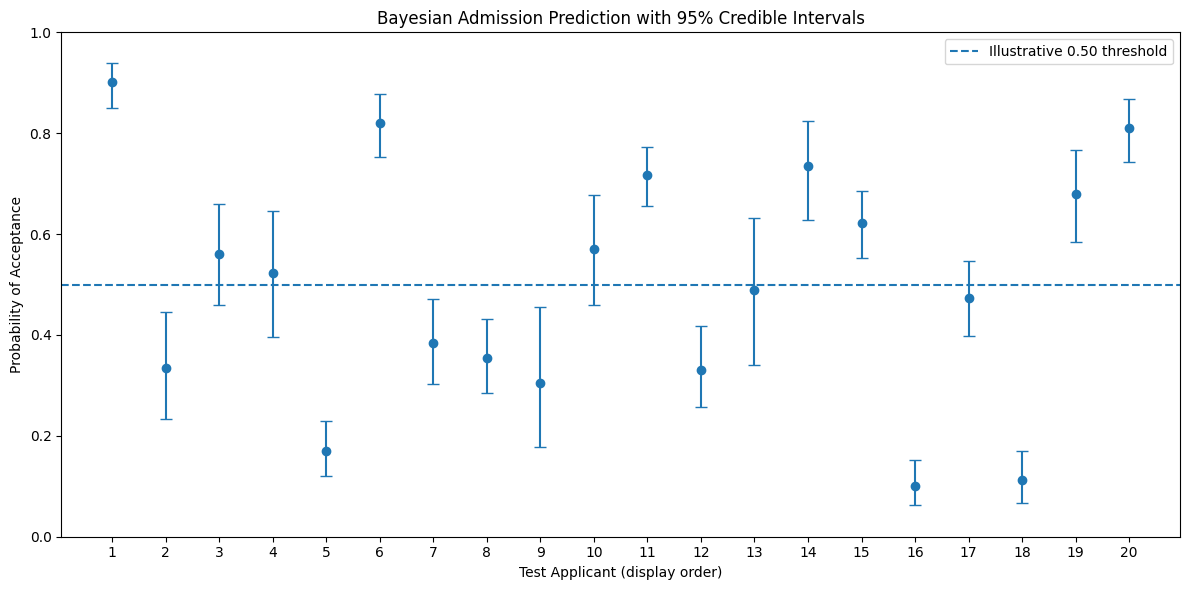

In [11]:
# Visualize the acceptance probabilities

plot_data = results.head(20).copy()

plt.figure(figsize=(12, 6))

x_positions = np.arange(len(plot_data))

plt.errorbar(
    x_positions,
    plot_data["Predicted_Acceptance_Probability"],
    yerr=[
        plot_data["Predicted_Acceptance_Probability"]
        - plot_data["Lower_95_CrI"],
        plot_data["Upper_95_CrI"]
        - plot_data["Predicted_Acceptance_Probability"]
    ],
    fmt="o",
    capsize=4
)

plt.axhline(
    0.50,
    linestyle="--",
    label="Illustrative 0.50 threshold"
)

plt.xticks(x_positions, plot_data.index + 1)

plt.xlabel("Test Applicant (display order)")
plt.ylabel("Probability of Acceptance")
plt.title(
    "Bayesian Admission Prediction with 95% Credible Intervals"
)

plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
# Evaluate the Bayesian model

y_test_array = y_test.to_numpy()

# Convert probabilities into binary predictions
y_pred = (
    probability_mean >= 0.50
).astype(int)

# Calculate evaluation metrics
accuracy = accuracy_score(
    y_test_array, y_pred
)

precision = precision_score(
    y_test_array, y_pred, zero_division=0
)

recall = recall_score(
    y_test_array, y_pred, zero_division=0
)

f1 = f1_score(
    y_test_array, y_pred, zero_division=0
)

auc = roc_auc_score(
    y_test_array, probability_mean
)

brier = brier_score_loss(
    y_test_array, probability_mean
)

logloss = log_loss(
    y_test_array, probability_mean
)

print("BAYESIAN MODEL EVALUATION")
print("-" * 40)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")
print(f"Brier Score: {brier:.4f}")
print(f"Log Loss:    {logloss:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_array,
        y_pred,
        labels=[0, 1],
        target_names=["Rejected", "Accepted"],
        zero_division=0
    )
)

print("Confusion Matrix:")
print(
    confusion_matrix(
        y_test_array,
        y_pred,
        labels=[0, 1]
    )
)

BAYESIAN MODEL EVALUATION
----------------------------------------
Accuracy:  0.6550
Precision: 0.6406
Recall:    0.4713
F1 Score:  0.5430
ROC-AUC:   0.7111
Brier Score: 0.2094
Log Loss:    0.6034

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.66      0.80      0.72       113
    Accepted       0.64      0.47      0.54        87

    accuracy                           0.66       200
   macro avg       0.65      0.63      0.63       200
weighted avg       0.65      0.66      0.64       200

Confusion Matrix:
[[90 23]
 [46 41]]


In [13]:
# Examine the effect of prior knowledge on the model

# Summarize posterior coefficient samples
beta_samples_array = beta_samples

coefficient_results = []

for j, feature in enumerate(features):

    samples = beta_samples_array[:, j]

    coefficient_results.append({
        "Feature": feature,
        "Posterior_Mean": samples.mean(),
        "Lower_95_CrI": np.quantile(samples, 0.025),
        "Upper_95_CrI": np.quantile(samples, 0.975),
        "Odds_Ratio": np.exp(samples.mean()),
        "OR_Lower_95": np.exp(
            np.quantile(samples, 0.025)
        ),
        "OR_Upper_95": np.exp(
            np.quantile(samples, 0.975)
        ),
        "Probability_Positive": np.mean(samples > 0)
    })

coefficient_results = pd.DataFrame(
    coefficient_results
)

print("Posterior coefficient interpretation:")
display(coefficient_results.round(4))

Posterior coefficient interpretation:


,Feature,Posterior_Mean,Lower_95_CrI,Upper_95_CrI,Odds_Ratio,OR_Lower_95,OR_Upper_95,Probability_Positive
0,GRE Score,0.3119,0.1494,0.4784,1.3660,1.1611,1.6134,0.9998
1,TOEFL Score,0.2849,0.1295,0.4415,1.3296,1.1383,1.5550,1.0000
2,University Rating,0.1623,-0.0012,0.3243,1.1762,0.9988,1.3830,0.9740
3,SOP,0.2731,0.1081,0.4375,1.3140,1.1142,1.5488,0.9995
4,LOR,0.0905,-0.0775,0.2544,1.0947,0.9254,1.2896,0.8570
5,CGPA,0.3332,0.1639,0.5011,1.3954,1.1781,1.6506,1.0000
6,Research,0.2695,0.1137,0.4258,1.3093,1.1204,1.5308,0.9992


In [14]:
# Predict the acceptance probability for a new applicant

new_applicant = pd.DataFrame([{
    "GRE Score": 325,
    "TOEFL Score": 110,
    "University Rating": 4,
    "SOP": 4.0,
    "LOR": 4.0,
    "CGPA": 9.0,
    "Research": 1
}])

# Apply the same training scaler
new_applicant_scaled = scaler.transform(
    new_applicant[features]
)

# Calculate probability for each posterior draw
new_log_odds = (
    alpha_samples
    + beta_samples @ new_applicant_scaled[0]
)

new_probability_draws = expit(new_log_odds)

# Posterior probability summary
predicted_probability = new_probability_draws.mean()

lower_interval = np.quantile(
    new_probability_draws, 0.025
)

upper_interval = np.quantile(
    new_probability_draws, 0.975
)

print("NEW APPLICANT PREDICTION")
print("-" * 40)

print(
    f"Estimated acceptance probability: "
    f"{predicted_probability:.2%}"
)

print(
    f"95% credible interval: "
    f"{lower_interval:.2%} to {upper_interval:.2%}"
)

if predicted_probability >= 0.50:
    print("Illustrative classification: Accepted")
else:
    print("Illustrative classification: Rejected")

NEW APPLICANT PREDICTION
----------------------------------------
Estimated acceptance probability: 70.15%
95% credible interval: 64.04% to 75.71%
Illustrative classification: Accepted
